In [26]:
import torch
import numpy as np
import pandas as pd
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import random
import os

from data_setup import TESSDataset, create_dataloaders

In [2]:
RANDOM_SEED = 42

def set_seed(seed: int = 42):
    """Locks down all random number generators for strict reproducibility."""
    # 1. Set Python random seed
    random.seed(seed)
    
    # 2. Set Python environment seed
    os.environ['PYTHONHASHSEED'] = str(seed)
    
    # 3. Set NumPy seed
    np.random.seed(seed)
    
    # 4. Set PyTorch CPU seed
    torch.manual_seed(seed)
    
    # 5. Set PyTorch Apple Silicon (MPS) seed
    if torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)
        
    # 6. Set PyTorch CUDA seeds (Standard practice to include for portability)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

In [3]:
# Setup device agnostic
device = "mps" if torch.backends.mps.is_available() else "cpu"
device

'mps'

In [4]:
if device == 'mps':
    torch.mps.manual_seed(RANDOM_SEED)

In [5]:
csv_path = "data/processed_labels.csv"
data_dir = "data/lightcurves"

BATCH_SIZE = 32

In [6]:
import pandas as pd
df_check = pd.read_csv("data/processed_labels.csv")
print(df_check.columns)

Index(['TIC_ID', 'final_label', 'Period (days)', 'Epoch (BJD)'], dtype='object')


In [7]:
train_dataloader, test_dataloader = create_dataloaders(
    csv_path = csv_path,
    data_dir = data_dir,
    batch_size = BATCH_SIZE
)

train_dataloader, test_dataloader

Dataset initialized with 1827 strictly synced samples.
Dataset initialized with 457 strictly synced samples.


(<torch.utils.data.dataloader.DataLoader at 0x115a1ed20>,
 <torch.utils.data.dataloader.DataLoader at 0x11546bd70>)

In [8]:
print(f"Number of training batches: {len(train_dataloader)}")
print(f"Number of testing batches: {len(test_dataloader)}")

Number of training batches: 58
Number of testing batches: 15


In [9]:
# Get a feature and label from the custom DataLoader
train_features_batch, train_labels_batch = next(iter(train_dataloader))
train_features_batch.shape, train_labels_batch.shape

(torch.Size([32, 1, 20000]), torch.Size([32]))

In [10]:
def accuracy_fn(y_true, y_pred):
    y_pred_rounded = torch.round(y_pred)
    
    y_true_int = y_true.cpu().int()
    y_pred_int = y_pred_rounded.cpu().int()
    
    correct = torch.eq(y_true_int, y_pred_int).sum().item() 
    
    acc = (correct / len(y_pred)) * 100 
    return acc

Dataset initialized with 1827 strictly synced samples.


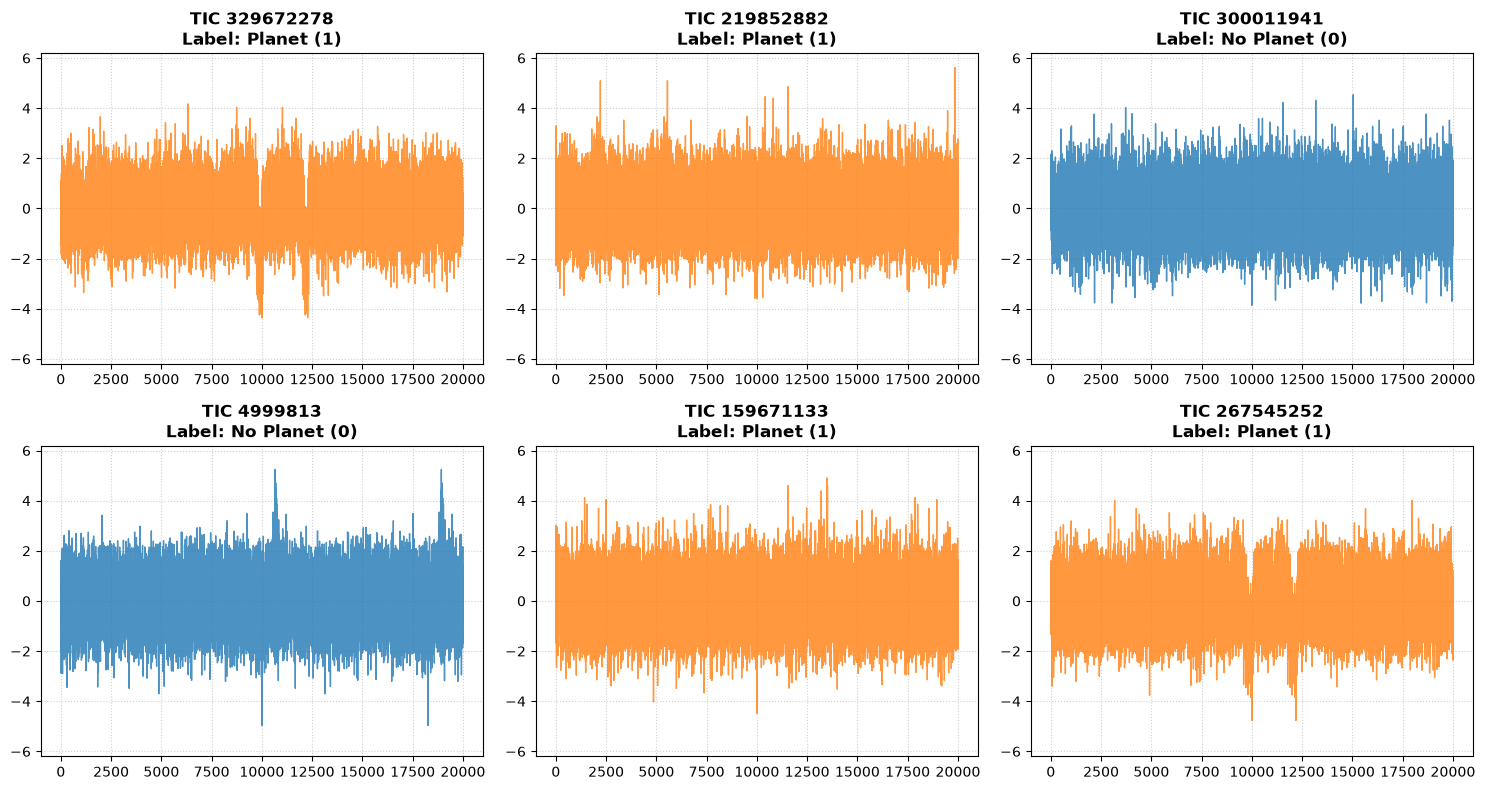

In [14]:
from torch.utils.data import DataLoader

# Fresh dataset instance that also hands back TIC_ID, so the plotted
# lightcurve, label, and ID are guaranteed to come from the same sample —
# regardless of shuffling. Doesn't touch your actual training dataloader.
debug_dataset = TESSDataset(
    labels_df = train_dataloader.dataset.labels_df,
    lightcurves_dir = data_dir,
    transform = None,      # no shift/noise while inspecting — see raw phase-folded shape
    return_id = True
)
debug_loader = DataLoader(debug_dataset, batch_size = 6, shuffle = True)

X_batch, y_batch, tic_batch = next(iter(debug_loader))

"""
X_batch = X_batch - 1.0
X_batch = torch.clamp(X_batch, min = -0.1, max = 0.1)
X_batch = X_batch * 10.0
"""
mean = X_batch.mean(dim = 2, keepdim = True)
std = X_batch.std(dim = 2, keepdim = True)
X_batch = (X_batch - mean) / (std + 1e-8)

X_vis, y_vis, tic_vis = X_batch.numpy(), y_batch.numpy(), tic_batch.numpy()

fig, axes = plt.subplots(2, 3, figsize = (15, 8))
axes = axes.flatten()

for i in range(6):
    lightcurve = X_vis[i].squeeze()
    label = int(y_vis[i].item())
    tic_id = int(tic_vis[i])

    color = '#ff7f0e' if label == 1 else '#1f77b4'
    axes[i].plot(lightcurve, color = color, alpha = 0.8, linewidth = 1)
    axes[i].set_title(f"TIC {tic_id}\nLabel: {'Planet (1)' if label else 'No Planet (0)'}", fontweight = 'bold')
    axes[i].set_ylim(-6.2, 6.2)
    axes[i].grid(True, linestyle = ':', alpha = 0.6)

plt.tight_layout()
plt.show()

Scanning training lightcurves for transit centers...


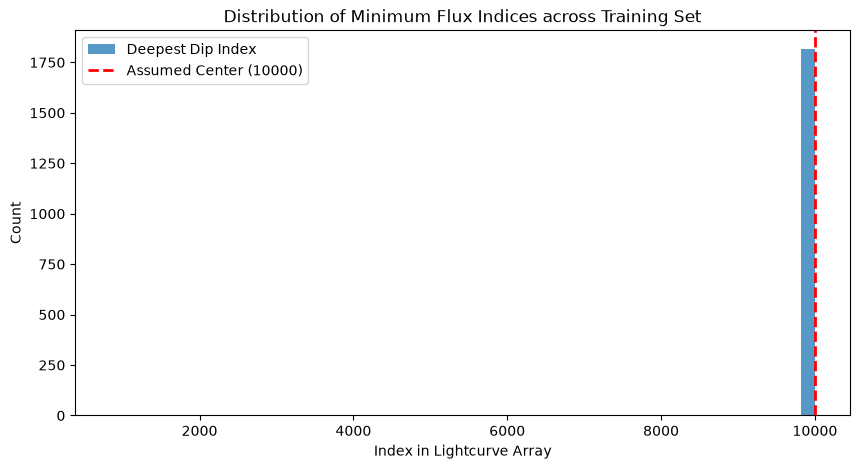

Total files scanned: 1827
Files centered within the 7000-13000 window: 1817 (99.5%)


In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Extract the raw DataFrame directly from the DataLoader's dataset
train_df = train_dataloader.dataset.labels_df 

# 1. Initialize the list to store minimum flux indices
argmins = []

print("Scanning training lightcurves for transit centers...")

# 2. Loop through the training dataframe
for _, row in train_df.iterrows():
    try:
        # Load the raw numpy lightcurve array
        arr = np.load(f"data/lightcurves/TIC_{int(row['TIC_ID'])}.npy")
        
        # Find the index of the absolute lowest point (the deepest part of the transit)
        argmins.append(np.argmin(arr))
    except FileNotFoundError:
        continue

# 3. Plot the alignment histogram
plt.figure(figsize=(10, 5))
plt.hist(argmins, bins=50, alpha=0.75, label='Deepest Dip Index')
plt.axvline(10000, color='red', linestyle='--', linewidth=2, label='Assumed Center (10000)')
plt.title("Distribution of Minimum Flux Indices across Training Set")
plt.xlabel("Index in Lightcurve Array")
plt.ylabel("Count")
plt.legend()
plt.show()

# 4. Print out explicit stats
argmins = np.array(argmins)
within_window = np.sum((argmins >= 9000) & (argmins <= 11000))
total_files = len(argmins)
print(f"Total files scanned: {total_files}")
print(f"Files centered within the 7000-13000 window: {within_window} ({within_window/total_files:.1%})")

In [15]:
planet_argmins, noplanet_argmins = [], []

for _, row in train_df.iterrows():
    arr = np.load(f"data/lightcurves/TIC_{int(row['TIC_ID'])}.npy")
    idx = int(np.argmin(arr))
    (planet_argmins if row['final_label'] == 1 else noplanet_argmins).append(idx)

p_centered = sum(7000 <= i <= 13000 for i in planet_argmins)
n_centered = sum(7000 <= i <= 13000 for i in noplanet_argmins)

print(f"Planet centered:    {p_centered}/{len(planet_argmins)} ({100*p_centered/len(planet_argmins):.1f}%)")
print(f"No-Planet centered: {n_centered}/{len(noplanet_argmins)} ({100*n_centered/len(noplanet_argmins):.1f}%)")

Planet centered:    944/952 (99.2%)
No-Planet centered: 873/875 (99.8%)


In [11]:
import torch
import torch.nn as nn

class TESSModelV3(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv_block_1 = nn.Sequential(
            nn.Conv1d(
                in_channels = 1,
                out_channels = 16,
                kernel_size = 16,
                stride = 2,
                padding = 7
            ),
            nn.BatchNorm1d(16),
            nn.LeakyReLU(negative_slope = 0.1),
            nn.AvgPool1d(kernel_size = 4) 
        )

        self.conv_block_2 = nn.Sequential(
            nn.Conv1d(
                in_channels = 16,
                out_channels = 32,
                kernel_size = 8,
                stride = 2,
                padding = 1
            ),
            nn.BatchNorm1d(32),
            nn.LeakyReLU(negative_slope = 0.1),
            nn.AvgPool1d(kernel_size = 4)
        )

        self.conv_block_3 = nn.Sequential(
            nn.Conv1d(
                in_channels = 32,
                out_channels = 64,
                kernel_size = 4,
                stride = 2
            ),
            nn.BatchNorm1d(64),
            nn.LeakyReLU(negative_slope = 0.1),
            nn.AvgPool1d(kernel_size = 28, stride = 1)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p = 0.2),
            nn.Linear(
                in_features = 8192,
                out_features = 64
            ),
            nn.LeakyReLU(negative_slope = 0.1),
            nn.Dropout(p = 0.1),
            nn.Linear(
                in_features = 64,
                out_features = 1
            ),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.classifier(self.conv_block_3(self.conv_block_2(self.conv_block_1(x))))
        

In [12]:
model_3 = TESSModelV3().to(device)
model_3

TESSModelV3(
  (conv_block_1): Sequential(
    (0): Conv1d(1, 16, kernel_size=(16,), stride=(2,), padding=(7,))
    (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.1)
    (3): AvgPool1d(kernel_size=(4,), stride=(4,), padding=(0,))
  )
  (conv_block_2): Sequential(
    (0): Conv1d(16, 32, kernel_size=(8,), stride=(2,), padding=(1,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.1)
    (3): AvgPool1d(kernel_size=(4,), stride=(4,), padding=(0,))
  )
  (conv_block_3): Sequential(
    (0): Conv1d(32, 64, kernel_size=(4,), stride=(2,))
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.1)
    (3): AvgPool1d(kernel_size=(28,), stride=(1,), padding=(0,))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dro

In [13]:
loss_fn = nn.BCELoss()
optimizer = torch.optim.Adam(model_3.parameters(), lr = 0.0001, weight_decay = 1e-5)

In [14]:
epochs = 10

for epoch in range(epochs):
    model_3.train()
    train_loss, train_accuracy = 0, 0

    for batch, (X, y) in enumerate(train_dataloader):
        X, y = X.to(device), y.to(device)

        # Since BCE loss expects shape [32, 1] but y has shape [32], unsqueeze operation is required
        y = y.unsqueeze(dim = 1)

        mean = X.mean(dim = 2, keepdim = True)
        std = X.std(dim = 2, keepdim = True)
        X = (X - mean) / (std + 1e-8) # 1e-8 prevents division by zero errors

        y_pred = model_3(X)

        loss = loss_fn(y_pred, y)
        train_loss += loss

        accuracy = accuracy_fn(y_true = y, y_pred = y_pred)
        train_accuracy += accuracy

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

    train_loss /= len(train_dataloader)
    train_accuracy /= len(train_dataloader)

    print(f"Epoch: {epoch} | Train loss: {train_loss:.5f} | Train accuracy: {train_accuracy:.2f}%")
        

Epoch: 0 | Train loss: 0.68648 | Train accuracy: 55.66%
Epoch: 1 | Train loss: 0.67863 | Train accuracy: 58.36%
Epoch: 2 | Train loss: 0.67772 | Train accuracy: 58.85%
Epoch: 3 | Train loss: 0.67089 | Train accuracy: 60.13%
Epoch: 4 | Train loss: 0.67028 | Train accuracy: 58.55%
Epoch: 5 | Train loss: 0.67172 | Train accuracy: 58.74%
Epoch: 6 | Train loss: 0.66730 | Train accuracy: 59.58%
Epoch: 7 | Train loss: 0.66443 | Train accuracy: 60.66%
Epoch: 8 | Train loss: 0.66118 | Train accuracy: 61.12%
Epoch: 9 | Train loss: 0.66141 | Train accuracy: 60.73%


In [15]:
test_loss, test_accuracy = 0, 0

model_3.eval()
with torch.inference_mode():
    for X, y in test_dataloader:
        X, y = X.to(device), y.to(device)

        y = y.unsqueeze(dim = 1)

        mean = X.mean(dim = 2, keepdim = True)
        std = X.std(dim = 2, keepdim = True)
        X = (X - mean) / (std + 1e-8)

        test_pred = model_3(X)

        loss = loss_fn(test_pred, y)
        test_loss += loss

        accuracy = accuracy_fn(y_true = y, y_pred = test_pred)
        test_accuracy += accuracy

    test_loss /= len(test_dataloader)
    test_accuracy /= len(test_dataloader)

print(f"Final Test loss: {test_loss:.5f} | Final Test accuracy: {test_accuracy:.2f}%")

Final Test loss: 0.70346 | Final Test accuracy: 54.38%


## Implementation of Checkpointing to capture the best model state

In [16]:
import torch
import torch.optim as optim
import copy

loss_fn = nn.BCELoss()
optimizer = optim.Adam(model_3.parameters(), lr = 0.0001, weight_decay = 1e-5)
epochs = 100

# Additional var to capture the best model state
best_test_loss = float('inf') # Initializing to inf so that the first loss value starts the process
best_model_weights = None
best_epoch = 0

for epoch in range(epochs):
    ### TRAINING
    model_3.train()
    train_loss, train_accuracy = 0, 0
    
    for X, y in train_dataloader:
        X, y = X.to(device), y.to(device)

        y = y.unsqueeze(dim = 1)
        
        y_pred = model_3(X)
        
        loss = loss_fn(y_pred, y)
        train_loss += loss.item()
        
        train_accuracy += accuracy_fn(y_true = y, y_pred = y_pred)
        
        optimizer.zero_grad()
        
        loss.backward()
        
        optimizer.step()
        
    train_loss /= len(train_dataloader)
    train_accuracy /= len(train_dataloader)
    
    ### TESTING
    model_3.eval()
    test_loss, test_accuracy = 0, 0
    
    with torch.inference_mode():
        for X_test, y_test in test_dataloader:
            X_test, y_test = X_test.to(device), y_test.to(device)

            y_test = y_test.unsqueeze(dim = 1)
            
            test_pred = model_3(X_test)
            loss = loss_fn(test_pred, y_test)
            
            test_loss += loss.item()
            test_accuracy += accuracy_fn(y_true = y_test, y_pred = test_pred)
            
        test_loss /= len(test_dataloader)
        test_accuracy /= len(test_dataloader)
        
    # Checkpointing implementation
    if test_loss < best_test_loss:
        best_test_loss = test_loss
        best_epoch = epoch
        
        # Copying weights to memory using copy.deepcopy to prevent them being overwritten
        best_model_weights = copy.deepcopy(model_3.state_dict())
        checkpoint_msg = "|Saved|"
        
    else:
        checkpoint_msg = ""
        
    # Print
    if (epoch + 1) % 5 == 0 or checkpoint_msg:
        print(f"Epoch {epoch} | Train Loss: {train_loss:.4f} Accuracy: {train_accuracy:.2f}% | Test Loss: {test_loss:.4f} Accuracy: {test_accuracy:.2f}% {checkpoint_msg}")

# Load the captured best state of the model
print(f"Best state captured at Epoch: {best_epoch}, test loss: {best_test_loss:.4f}")

# Overwrite model with captured best state
model_3.load_state_dict(best_model_weights)


Epoch 0 | Train Loss: 0.6838 Accuracy: 57.96% | Test Loss: 0.7046 Accuracy: 51.04% |Saved|
Epoch 3 | Train Loss: 0.6653 Accuracy: 60.93% | Test Loss: 0.6835 Accuracy: 56.04% |Saved|
Epoch 4 | Train Loss: 0.6686 Accuracy: 60.95% | Test Loss: 0.7156 Accuracy: 51.88% 
Epoch 6 | Train Loss: 0.6631 Accuracy: 60.85% | Test Loss: 0.6818 Accuracy: 57.29% |Saved|
Epoch 9 | Train Loss: 0.6573 Accuracy: 61.77% | Test Loss: 0.6928 Accuracy: 52.08% 
Epoch 14 | Train Loss: 0.6491 Accuracy: 61.77% | Test Loss: 0.6767 Accuracy: 56.67% |Saved|
Epoch 17 | Train Loss: 0.6506 Accuracy: 62.45% | Test Loss: 0.6637 Accuracy: 58.75% |Saved|
Epoch 19 | Train Loss: 0.6448 Accuracy: 61.38% | Test Loss: 0.6964 Accuracy: 49.17% 
Epoch 24 | Train Loss: 0.6417 Accuracy: 62.00% | Test Loss: 0.7018 Accuracy: 48.54% 
Epoch 29 | Train Loss: 0.6371 Accuracy: 63.98% | Test Loss: 0.6934 Accuracy: 57.08% 
Epoch 34 | Train Loss: 0.6341 Accuracy: 63.72% | Test Loss: 0.6865 Accuracy: 53.96% 
Epoch 35 | Train Loss: 0.6331 Accur

<All keys matched successfully>

               precision    recall  f1-score   support

No Planet (0)       0.64      0.47      0.54       219
   Planet (1)       0.61      0.75      0.67       237

     accuracy                           0.62       456
    macro avg       0.62      0.61      0.61       456
 weighted avg       0.62      0.62      0.61       456



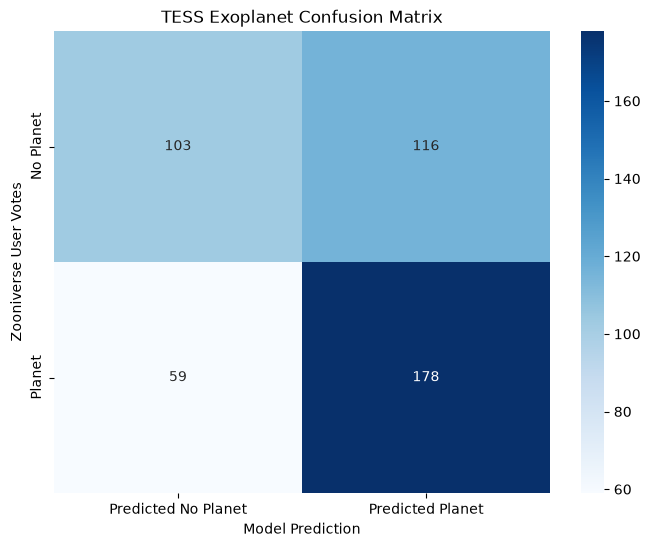

In [25]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

model_3.eval()

all_preds = []
all_true = []
all_probs = []

confidence = 0.51 # Tried different values in the range [0.35, 0.65]

with torch.inference_mode():
    for X_test, y_test in test_dataloader:
        X_test = X_test.to(device)
        
        test_logits = model_3(X_test).cpu().numpy()

        # Convert to binary predictions- 1 or 0
        b_preds = (test_logits >= confidence).astype(int)
        
        all_probs.extend(test_logits)
        all_preds.extend(b_preds)
        all_true.extend(y_test.cpu().numpy())

# Convert lists to numpy arrays for sklearn
all_true = np.array(all_true)
all_preds = np.array(all_preds)

# Create report
print(classification_report(all_true, all_preds, target_names = ['No Planet (0)', 'Planet (1)']))

# Cretae confusion matrix
cm = confusion_matrix(all_true, all_preds)

plt.figure(figsize = (8, 6))
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues', 
            xticklabels = ['Predicted No Planet', 'Predicted Planet'],
            yticklabels = ['No Planet', 'Planet'])

plt.title("TESS Exoplanet Confusion Matrix")
plt.ylabel("True label")
plt.xlabel("Model Prediction")
plt.show()

After doing probability distribution analysis of the model's predictions by trying different 'confidence' values, I observed that most of the model's predictions lie close to 0.5 (I came to this conclusion since chaning the confidence by a small amount near 0.5, such as 0.5 -> 0.52, changes the results significantly, but setting the confidence, to say 0.2, and making changes, such as 0.2 -> 0.25, does not change the results much).

This is not a good sign, since from this we can infer that the model is still extremely uncertain about it's predictions and it is performing only marginally better than complete random guessing.

The potential issue which I indentified which may be causing this (hypothesis) is that the amount of Pooling inside the convolutional blocks of the model is more or less erasing the transit data, which only lasts for a small interval of time compared to entire time series data. On the other hand, I cannot remove the pooling layers, since the memory of my device is limited and will quickly run out.

A proposed solution I have for this is to focus the model on the center of the timeseries data, where the phase folded transit signal (if one exists) lies. Cropping out the rest of the data will effectively remove most of the necessity for the pooling layers, which still preserving the transit signal.

In [23]:
class TESSModelV4(nn.Module):
    def __init__(self):
        super().__init__()

        self.global_view = nn.Sequential(
            nn.Conv1d(
                in_channels = 1,
                out_channels = 16, 
                kernel_size = 16,
                stride = 4
            ),
            nn.BatchNorm1d(16),
            nn.LeakyReLU(0.1),
            nn.AvgPool1d(kernel_size = 4),
            nn.Conv1d(
                in_channels = 16,
                out_channels = 32, 
                kernel_size = 8,
                stride = 2
            ),
            nn.BatchNorm1d(32),
            nn.LeakyReLU(0.1),
            nn.AvgPool1d(kernel_size = 4)
        )

        self.focused_view = nn.Sequential(
            nn.Conv1d(
                in_channels = 1,
                out_channels = 16, 
                kernel_size = 5,
                stride = 1
            ),
            nn.BatchNorm1d(16),
            nn.LeakyReLU(0.1),
            nn.AvgPool1d(kernel_size = 2),
            nn.Conv1d(
                in_channels = 16,
                out_channels = 32, 
                kernel_size = 5,
                stride = 1
            ),
            nn.BatchNorm1d(32),
            nn.LeakyReLU(0.1),
            nn.AvgPool1d(kernel_size = 2)
        )

        # Exact divisibility is required (Apple MPS issue) (documentation referred - https://github.com/pytorch/pytorch/issues/96056)
        # NOTE: Moved adaptive pooling layer to pool_branch function
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features = 128, out_features = 128),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.1),
            nn.Dropout(p = 0.2),
            nn.Linear(in_features = 128, out_features = 1),
            #nn.Sigmoid()
        )

    def pool_branch(self, feat):
        avg = F.adaptive_avg_pool1d(feat, 1).squeeze(-1)
        mn = -F.adaptive_max_pool1d(-feat, 1).squeeze(-1)
        return torch.cat([avg, mn], dim = 1)
        

    def forward(self, x):
        x_focused = x[:, :, 9000:11000] 

        global_output = self.global_view(x)
        focused_output = self.focused_view(x_focused)

        global_summary  = self.pool_branch(global_output)
        focused_summary = self.pool_branch(focused_output)
        merge_views = torch.cat([global_summary, focused_summary], dim = 1)

        return self.classifier(merge_views)        

In [17]:
set_seed(42)
model_4 = TESSModelV4().to(device)
model_4

TESSModelV4(
  (global_view): Sequential(
    (0): Conv1d(1, 16, kernel_size=(16,), stride=(4,))
    (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.1)
    (3): AvgPool1d(kernel_size=(4,), stride=(4,), padding=(0,))
    (4): Conv1d(16, 32, kernel_size=(8,), stride=(2,))
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): LeakyReLU(negative_slope=0.1)
    (7): AvgPool1d(kernel_size=(4,), stride=(4,), padding=(0,))
  )
  (focused_view): Sequential(
    (0): Conv1d(1, 16, kernel_size=(5,), stride=(1,))
    (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.1)
    (3): AvgPool1d(kernel_size=(2,), stride=(2,), padding=(0,))
    (4): Conv1d(16, 32, kernel_size=(5,), stride=(1,))
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=Tr

In [18]:
set_seed(42)

import torch
import torch.optim as optim
import copy

#loss_fn = FocalLoss(alpha = 0.75, gamma = 2.0)
loss_fn = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model_4.parameters(), lr = 0.001, weight_decay = 1e-5) ##

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, 
    mode = 'min', 
    factor = 0.5, 
    patience = 5
)

epochs = 100

# Additional var to capture the best model state
best_test_loss = float('inf') # Initializing to inf so that the first loss value starts the process
best_model_weights = None
best_epoch = 0

for epoch in range(epochs):
    ### TRAINING
    model_4.train()
    train_loss, train_accuracy = 0, 0
    
    for X, y in train_dataloader:
        X, y = X.to(device), y.to(device)

        # Z-Score Normalization
        mean = X.mean(dim = 2, keepdim = True)
        std = X.std(dim = 2, keepdim = True)
        X = (X - mean) / (std + 1e-8)
        
        """
        X = X - 1.0
        X = torch.clamp(X, min = -0.1, max = 0.1)
        X = X * 10.0
        """
        
        y = y.float().unsqueeze(dim = 1)
        
        y_pred = model_4(X)
        
        loss = loss_fn(y_pred, y)
        train_loss += loss.item()

        y_pred_probs = torch.sigmoid(y_pred)
        train_accuracy += accuracy_fn(y_true = y, y_pred = y_pred_probs)
        
        optimizer.zero_grad()
        
        loss.backward()
        
        optimizer.step()
        
    train_loss /= len(train_dataloader)
    train_accuracy /= len(train_dataloader)
    
    ### TESTING
    model_4.eval()
    test_loss, test_accuracy = 0, 0
    
    with torch.inference_mode():
        for X_test, y_test in test_dataloader:
            X_test, y_test = X_test.to(device), y_test.to(device)

            mean = X_test.mean(dim = 2, keepdim = True)
            std = X_test.std(dim = 2, keepdim = True)
            X_test = (X_test - mean) / (std + 1e-8)
            
            """
            X_test = X_test - 1.0
            X_test = torch.clamp(X_test, min = -0.1, max = 0.1)
            X_test = X_test * 10.0
            """

            y_test = y_test.float().unsqueeze(dim = 1)
            
            test_pred = model_4(X_test)
            
            loss = loss_fn(test_pred, y_test)
            test_loss += loss.item()

            test_pred_probs = torch.sigmoid(test_pred)
            test_accuracy += accuracy_fn(y_true = y_test, y_pred = test_pred_probs)
            
        test_loss /= len(test_dataloader)
        test_accuracy /= len(test_dataloader)

    scheduler.step(test_loss)
    current_lr = optimizer.param_groups[0]['lr']
        
    # Checkpointing implementation
    if test_loss < best_test_loss:
        best_test_loss = test_loss
        best_epoch = epoch
        
        # Copying weights to memory using copy.deepcopy to prevent them being overwritten
        best_model_weights = copy.deepcopy(model_4.state_dict())
        checkpoint_msg = "|Saved|"
        
    else:
        checkpoint_msg = ""
        
    # Print
    if (epoch + 1) % 5 == 0 or checkpoint_msg:
        print(f"Epoch {epoch} | LR: {current_lr:.8f} | Train Loss: {train_loss:.4f} Accuracy: {train_accuracy:.2f}% | Test Loss: {test_loss:.4f} Accuracy: {test_accuracy:.2f}% {checkpoint_msg}")

# Load the captured best state of the model
print(f"Best state captured at Epoch: {best_epoch}, test loss: {best_test_loss:.4f}")

# Overwrite model with captured best state
model_4.load_state_dict(best_model_weights)


Epoch 0 | LR: 0.00100000 | Train Loss: 0.6947 Accuracy: 53.38% | Test Loss: 0.6928 Accuracy: 56.30% |Saved|
Epoch 2 | LR: 0.00100000 | Train Loss: 0.6764 Accuracy: 56.23% | Test Loss: 0.6772 Accuracy: 51.50% |Saved|
Epoch 3 | LR: 0.00100000 | Train Loss: 0.6715 Accuracy: 57.08% | Test Loss: 0.6632 Accuracy: 55.76% |Saved|
Epoch 4 | LR: 0.00100000 | Train Loss: 0.6687 Accuracy: 58.42% | Test Loss: 0.7010 Accuracy: 56.18% 
Epoch 7 | LR: 0.00100000 | Train Loss: 0.6586 Accuracy: 61.12% | Test Loss: 0.6577 Accuracy: 60.58% |Saved|
Epoch 9 | LR: 0.00100000 | Train Loss: 0.6535 Accuracy: 59.36% | Test Loss: 0.6778 Accuracy: 57.66% 
Epoch 14 | LR: 0.00050000 | Train Loss: 0.6386 Accuracy: 63.15% | Test Loss: 0.6675 Accuracy: 61.32% 
Epoch 19 | LR: 0.00025000 | Train Loss: 0.6238 Accuracy: 64.71% | Test Loss: 0.6595 Accuracy: 61.41% 
Epoch 20 | LR: 0.00025000 | Train Loss: 0.6315 Accuracy: 64.46% | Test Loss: 0.6546 Accuracy: 63.61% |Saved|
Epoch 23 | LR: 0.00025000 | Train Loss: 0.6189 Accura

<All keys matched successfully>

Optimal threshold: 0.405
               precision    recall  f1-score   support

No Planet (0)       0.72      0.42      0.53       219
   Planet (1)       0.62      0.85      0.71       238

     accuracy                           0.65       457
    macro avg       0.67      0.64      0.62       457
 weighted avg       0.67      0.65      0.63       457



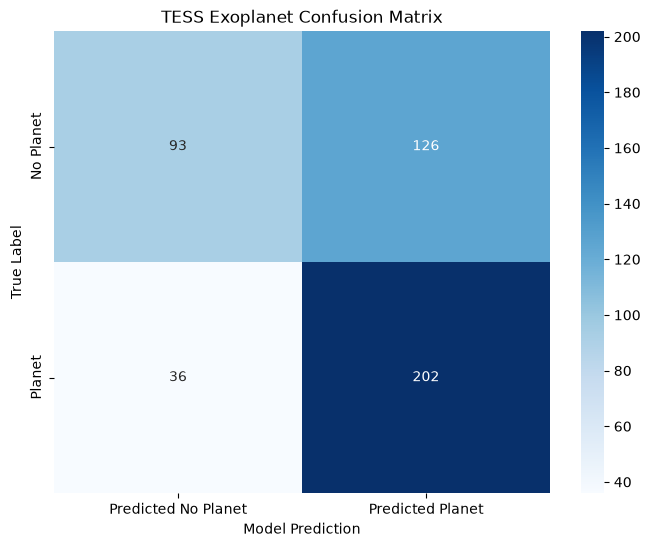

In [25]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, roc_curve

model_4.eval() ##

all_preds = []
all_true = []
all_probs = []
all_raw_flux = []

# re-run the confusion matrix using this threshold instead of a fixed 0.50
#b_preds_recalibrated = (np.array(all_probs) >= thresholds[best_idx]).astype(int)

#confidence = 0.516 # Tried different values in the range [0.35, 0.65]

with torch.inference_mode():
    for X_test, y_test in test_dataloader:
        X_test = X_test.to(device)

        all_raw_flux.append(X_test.cpu())

        mean = X_test.mean(dim = 2, keepdim = True)
        std = X_test.std(dim = 2, keepdim = True)
        X_test = (X_test - mean) / (std + 1e-8)
        
        """
        X_test = X_test - 1.0
        X_test = torch.clamp(X_test, min = -0.1, max = 0.1)
        X_test = X_test * 10.0
        """
        
        test_logits = model_4(X_test) ##
        test_probs = torch.sigmoid(test_logits).squeeze().cpu().numpy() 

        # Convert to binary predictions- 1 or 0
        #b_preds = (test_probs >= confidence).astype(int)

        if test_probs.ndim == 0:
            all_probs.append(test_probs)
            #b_preds = [b_preds]
        else:
            all_probs.extend(test_probs)
        
        #all_preds.extend(b_preds)
        
        # Squeeze y_test to guarantee it is a flat 1D array before extending
        all_true.extend(y_test.squeeze().cpu().numpy())

# Convert lists to numpy arrays for sklearn
all_true = np.array(all_true)
all_preds = np.array(all_preds)
X_test_raw = torch.cat(all_raw_flux)


fpr, tpr, thresholds = roc_curve(all_true, all_probs)
youden_j = tpr - fpr
best_idx = np.argmax(youden_j)
opt_threshold = thresholds[best_idx]
print(f"Optimal threshold: {opt_threshold:.3f}")

# re-run the confusion matrix using this threshold instead of a fixed 0.50
all_preds = (all_probs >= opt_threshold).astype(int)


# Create report
print(classification_report(all_true, all_preds, target_names = ['No Planet (0)', 'Planet (1)']))

# Cretae confusion matrix
cm = confusion_matrix(all_true, all_preds)

plt.figure(figsize = (8, 6))
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues', 
            xticklabels = ['Predicted No Planet', 'Predicted Planet'],
            yticklabels = ['No Planet', 'Planet'])

plt.title("TESS Exoplanet Confusion Matrix")
plt.ylabel("True Label")
plt.xlabel("Model Prediction")
plt.show()

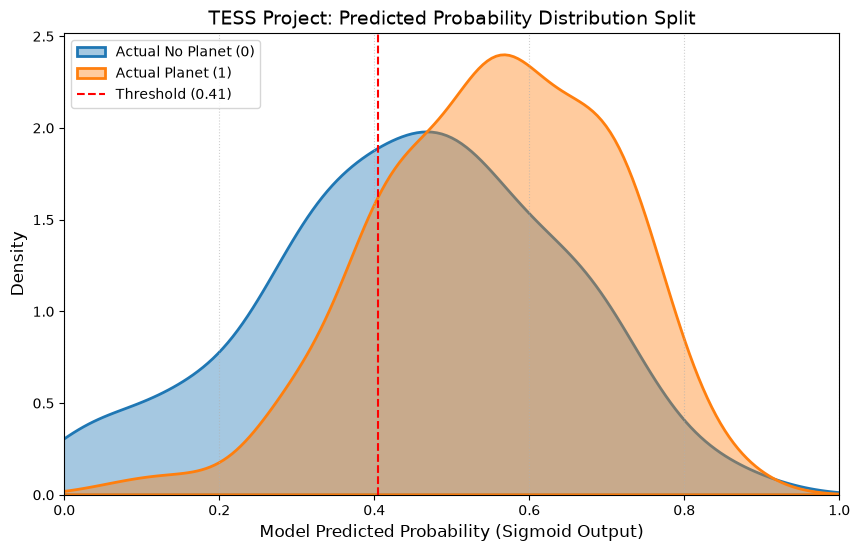

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Ensure arrays are numpy formats
probs_arr = np.array(all_probs)
true_arr = np.array(all_true)

plt.figure(figsize=(10, 6))

# Plot KDE for Negative Class (No Planet)
sns.kdeplot(
    probs_arr[true_arr == 0], 
    label = 'Actual No Planet (0)', 
    fill = True, 
    alpha = 0.4,
    linewidth = 2
)

# Plot KDE for Positive Class (Planet)
sns.kdeplot(
    probs_arr[true_arr == 1], 
    label = 'Actual Planet (1)', 
    fill = True, 
    alpha = 0.4,
    linewidth = 2
)

# Draw the current decision threshold line
plt.axvline(x = opt_threshold, color = 'red', linestyle = '--', label = f'Threshold ({opt_threshold:.2f})')

plt.title('TESS Project: Predicted Probability Distribution Split', fontsize = 14)
plt.xlabel('Model Predicted Probability (Sigmoid Output)', fontsize = 12)
plt.ylabel('Density', fontsize = 12)
plt.xlim(0, 1)
plt.legend(loc = 'upper left')
plt.grid(axis = 'x', linestyle = ':', alpha = 0.6)
plt.show()

In [21]:
# compute depth from raw (untransformed) flux for each test sample, then bucket
depths = 1.0 - X_test_raw.amin(dim=2).squeeze().cpu().numpy()  # before the -1/clamp/*10 transform
shallow_mask = (true_arr == 1) & (depths < 0.01)
deep_mask    = (true_arr == 1) & (depths >= 0.03)

print("Shallow planets — mean predicted prob:", probs_arr[shallow_mask].mean())
print("Deep planets — mean predicted prob:", probs_arr[deep_mask].mean())

Shallow planets — mean predicted prob: 0.5431629
Deep planets — mean predicted prob: 0.5580843


In [22]:
shallow_np_mask = (true_arr == 0) & (depths < 0.01)
deep_np_mask    = (true_arr == 0) & (depths >= 0.03)

print("Shallow No-Planet — mean predicted prob:", probs_arr[shallow_np_mask].mean())
print("Deep No-Planet — mean predicted prob:", probs_arr[deep_np_mask].mean())

Shallow No-Planet — mean predicted prob: 0.4564697
Deep No-Planet — mean predicted prob: 0.39875856
